In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/DataSets/insurance.csv'
insurance_data = pd.read_csv(path)

In [ ]:
insurance_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


The variables of this dataset are:
1. Age: Age column represents the Age of the primary beneficiary.It is Number(int64).

2. Sex : Sex column represents the Gender of the member. It is String(as it is a string it is shown as object).

3. BMI : BMI represtens the Body mass index ($kg/m^2$), providing an understanding of body weights that are relatively high or low relative to height. It is a Number(float64).

4. Children: Children field represents the Number of children covered by health insurance / Number of dependents. It is a number(int64).

5. Smoker: Smoker column represents whether the individual smokes or not.It is a Yes/No column(Object).

6. Region: Region represents the region the individual belong to. It is a string(as it is a string it is shown as object).

7. Charges: Charges represent the individual's medical costs billed by health insurance

In [ ]:
insurance_data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


# Types of variables in the dataset:

#### Quantitative Variables:

1. Discrete

    a. age

    b. children

2. Continuous

    a. bmi

    b. charges

#### Qualitative Variables:

1. Nominal

    a. sex

    b. smoker

    c. region

2. Ordinal

    There are no ordinal variable in this dataset.

***Note*** : The target variable is a Continuous variable.

# Let us check for the data quality :

##### Null Check :

In [ ]:
print(insurance_data.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Observation : We do not have null values in the data set.

##### Duplicates:

In [ ]:
dup_cnt = insurance_data.duplicated().sum()

print(f"The Number of duplicates are: {dup_cnt}  ")

The Number of duplicates are: 1  


In [ ]:
dup_df = insurance_data[insurance_data.duplicated(keep=False)]

print("--- The Duplicate Rows ---")
display(dup_df)

--- The Duplicate Rows ---


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [ ]:
insurance_data.drop_duplicates(inplace=True)

In [ ]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   object 
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 83.6+ KB


##### Numerical Variable Quality Check:

In [ ]:
insurance_data[['age','bmi','children','charges']].describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


Observations:

##### Categorical Variables Quality Check:

In [ ]:
#Creating the list of categorical variables.
Cat_variables = ['sex','smoker','region']

for col in Cat_variables:
  print(f'\n---Unique values in {col}---')
  print(insurance_data[col].unique())



---Unique values in sex---
['female' 'male']

---Unique values in smoker---
['yes' 'no']

---Unique values in region---
['southwest' 'southeast' 'northwest' 'northeast']


Observations:

Univarient:

Numerical variables:

In [ ]:
insurance_data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

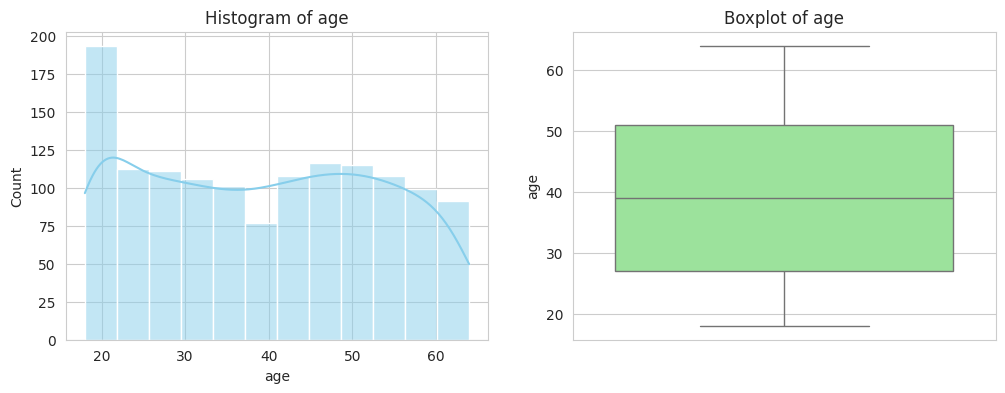

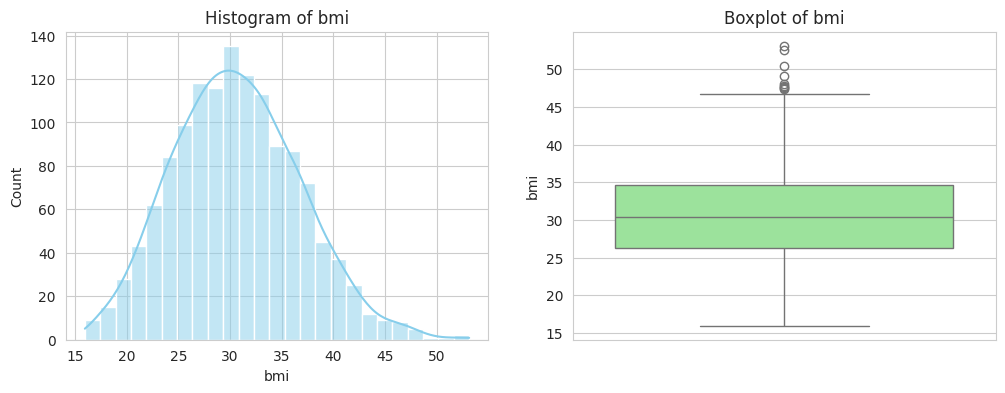

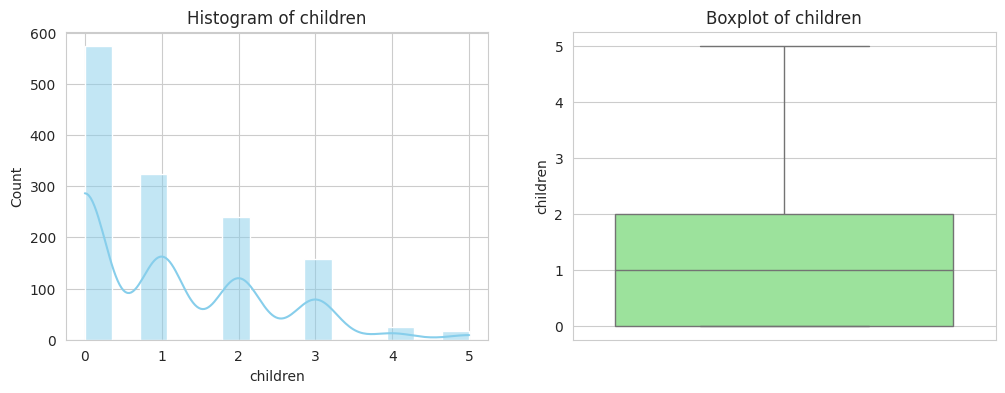

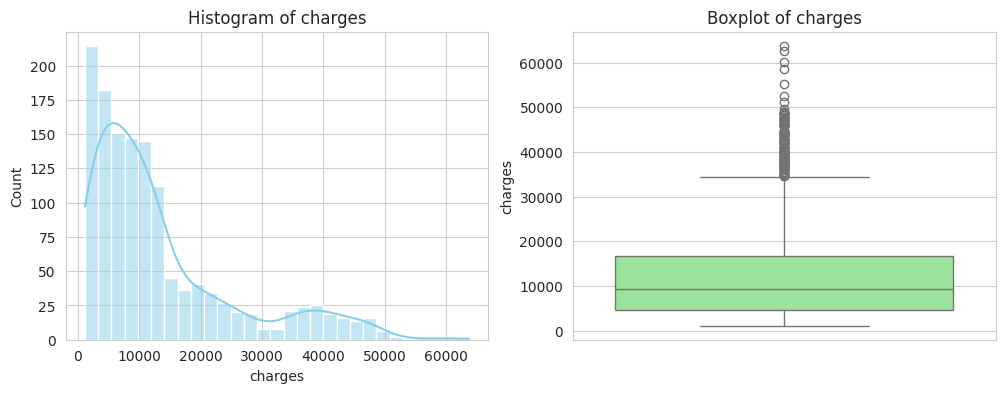

In [ ]:
num_var = ['age','bmi','children','charges']

# Set the visual style
sns.set_style("whitegrid")

for col in num_var:
  fig, axes = plt.subplots(1,2,figsize=(12,4))

  # Histogram : Checks for Skew (Is it a Bell Curve?)
  sns.histplot(data = insurance_data, x=col, kde=True, ax=axes[0], color='skyblue')
  axes[0].set_title(f'Histogram of {col}')

  # Boxplot : Checks for Outliers
  sns.boxplot(data=insurance_data, y=col, ax=axes[1],color='lightgreen')
  axes[1].set_title(f'Boxplot of {col}')

#  # plt.tight_layout

  plt.show()

Observations:

Categorical variables:

We use this to see if we have enough data for each group

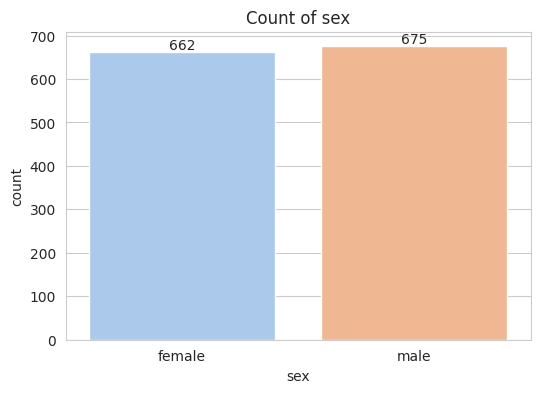

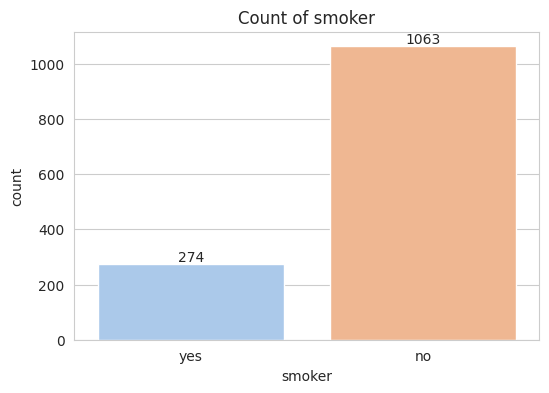

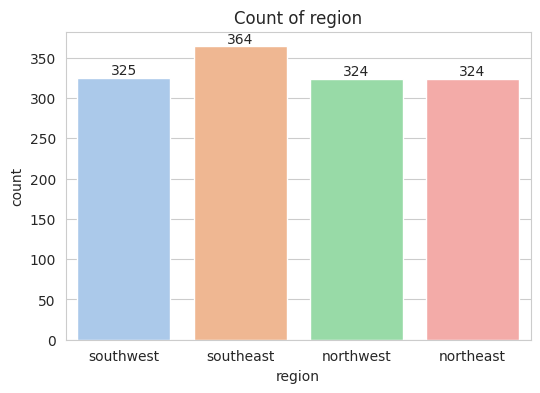

In [ ]:
Cat_var = ['sex','smoker','region']

for col in Cat_var:
  plt.figure(figsize=(6, 4))

  # Count Plot: Checks how many rows we have for each category
  # We add labels so you can see the exact count
  ax = sns.countplot(data = insurance_data, x = col, hue=col, legend = False, palette = 'pastel')
  for container in ax.containers:
    ax.bar_label(container)

  plt.title(f'Count of {col}')
  plt.show()

Observations:


Bivariate Analysis

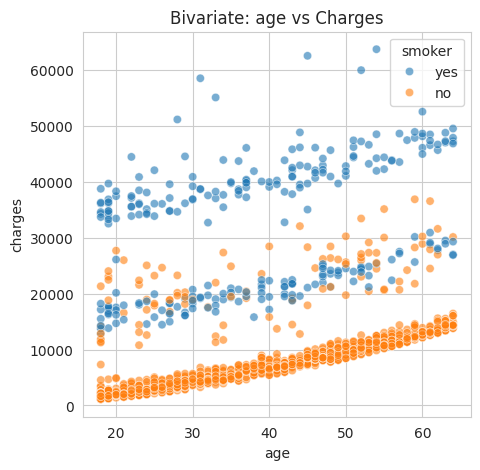

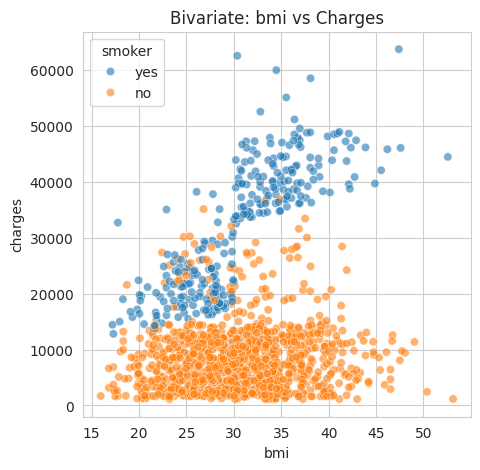

In [ ]:
sns.set_style("whitegrid")

# --- 1. CONTINUOUS Variables (Scatter Plots) ---
# We use Scatter Plots for fluid numbers like Age and BMI
continuous_cols = ['age', 'bmi']

for col in continuous_cols:
    plt.figure(figsize=(5,5))
    sns.scatterplot(data=insurance_data,x=col,y='charges',hue='smoker',legend = True,color='blue',alpha=0.6)
    plt.title(f'Bivariate: {col} vs Charges')
    plt.show()

Observations:


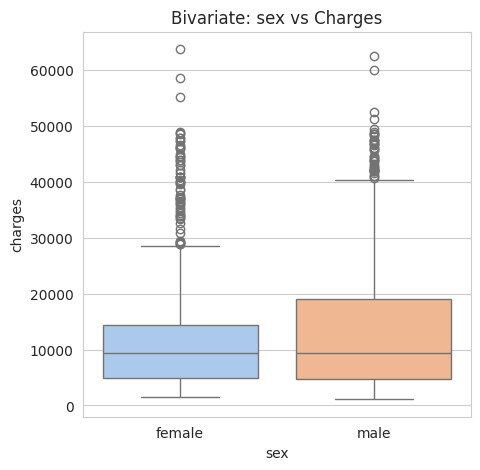

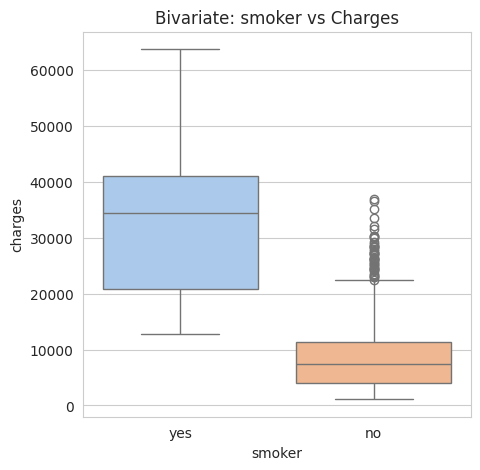

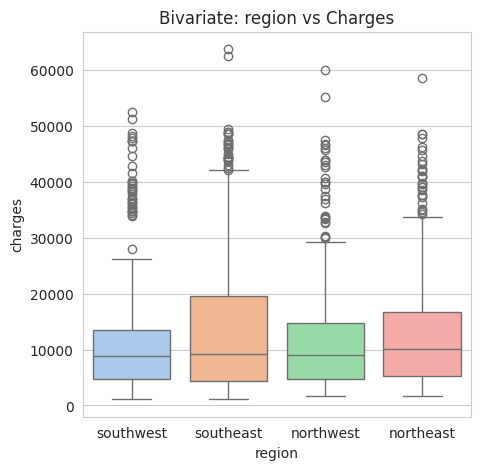

In [ ]:
Cat_var = ['sex','smoker','region']

for col in Cat_var:
  plt.figure(figsize=(5,5))
  sns.boxplot(data=insurance_data,x=col,y='charges',hue=col,legend=False,palette='pastel')
  plt.title(f'Bivariate: {col} vs Charges')
  plt.show()

In [ ]:
group_stats = insurance_data.groupby('sex')['charges'].agg(['mean', 'median'])
print(group_stats)

                mean     median
sex                            
female  12569.578844  9412.9625
male    13974.998864  9377.9047


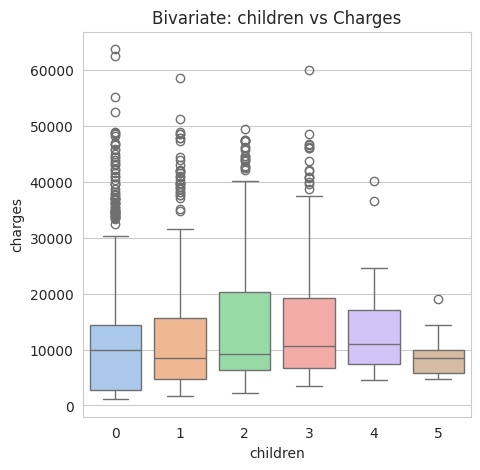

In [ ]:
plt.figure(figsize=(5,5))
sns.boxplot(data=insurance_data,x='children',y='charges',hue='children',legend=False,palette='pastel')
plt.title(f'Bivariate: {'children'} vs Charges')
plt.show()

Observations:


Preprocessing

In [ ]:
insurance_data['sex'].unique()

array(['female', 'male'], dtype=object)

In [ ]:
# 1. Create the 'Clean' dataframe
insurance_data_clean = insurance_data.copy()

# 2. Convert Binary Categories (Mapping)
# We turn words into 1s and 0s
insurance_data_clean['smoker'] = insurance_data_clean['smoker'].map({'yes':1 , 'no':0})
insurance_data_clean['sex'] = insurance_data_clean['sex'].map({'male':1, 'female':0})

# 3. Convert Nominal Categories (One-Hot Encoding)
# This creates new columns for regions and drops the old text column
insurance_data_clean = pd.get_dummies(insurance_data_clean, columns=['region'], drop_first=True)

#print("Preprocessed Columns:", insurance_data_clean.columns.tolist())
insurance_data_clean.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,False,False,True
1,18,1,33.770,1,0,1725.55230,False,True,False
2,28,1,33.000,3,0,4449.46200,False,True,False
3,33,1,22.705,0,0,21984.47061,True,False,False
4,32,1,28.880,0,0,3866.85520,True,False,False


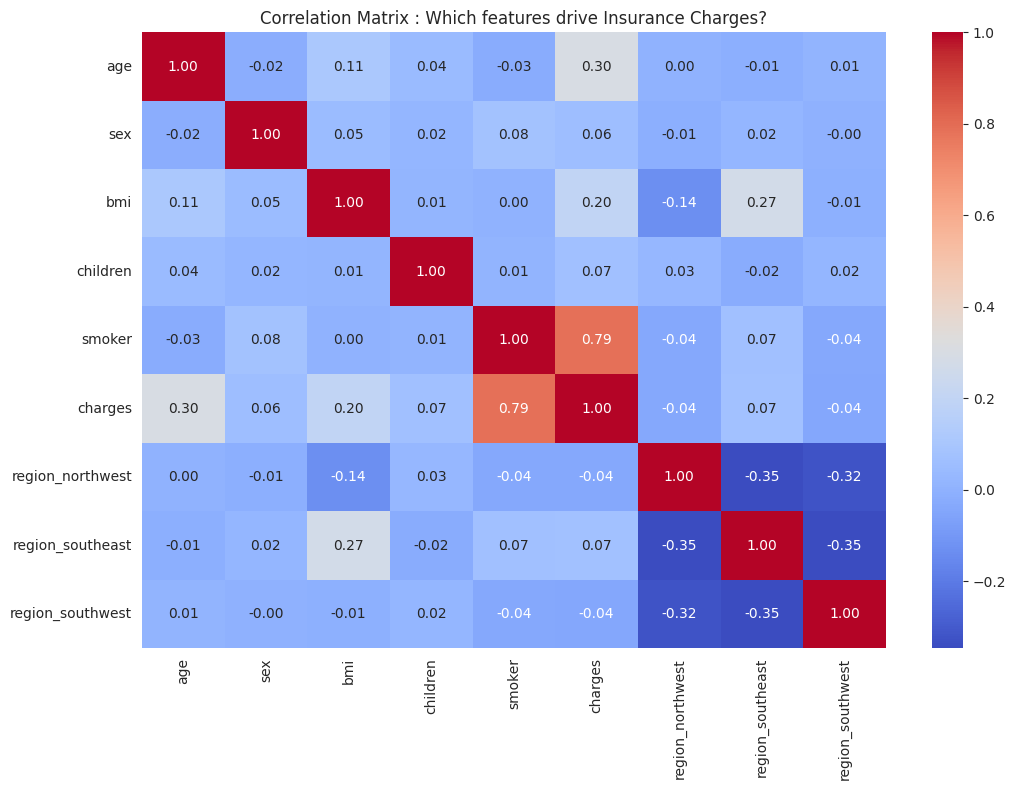

In [ ]:
plt.figure(figsize=(12,8))

# 1. Calculate the Correlation Matrix on your clean data
# .corr() calculates the relationship between every pair of columns
corr_matrix = insurance_data_clean.corr()

# 2. Draw the Heatmap
# annot=True: Writes the actual correlation number inside each box
# cmap='coolwarm': High positive is Red, High negative is Blue, Near zero is White
# fmt=".2f": Rounds the numbers to 2 decimal places
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Correlation Matrix : Which features drive Insurance Charges?")
plt.show()



In [ ]:
# 1. Define your Inputs (X) and your Target (Y)
X = insurance_data_clean.drop('charges',axis=1)
Y = insurance_data_clean['charges']

# 2. Perform the Split
# test_size=0.2 means 20% for testing, 80% for training
# random_state=42 is like a "seed" - it ensures we get the same shuffle every
# time we run it

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

# 3. Verify the sizes
print(f"Total Rows: {len(insurance_data_clean)}")
print(f"Training set: {X_train.shape[0]} people")
print(f"Testing set: {X_test.shape[0]} people")

Total Rows: 1337
Training set: 1069 people
Testing set: 268 people


In [ ]:
# 1. Instantiate the Model
# We are creating an "empty brain" named 'model'
model = LinearRegression()

# 2. The Fit (Training)
# This is the "Study Phase". The model looks at the training data
# to learn the relationship between features and charges.
model.fit(X_train , Y_train)


# Let's look at the "Weights" (Coefficients)
weights = pd.DataFrame({'Feature': X.columns, 'Weight': model.coef_})
print(weights.sort_values(by='Weight', ascending=False))

# 3. The Predict (Testing)
# Now we ask the model to guess the charges for our test set (the Final Exam)
# These are the "AI's Guesses"
predictions = model.predict(X_test)

print("Training Complete. The AI has finished its 'Final Exam'.")

            Feature        Weight
4            smoker  23077.764593
3          children    533.009989
2               bmi    318.701441
0               age    248.210720
1               sex   -101.542054
5  region_northwest   -391.761455
7  region_southwest   -659.139752
6  region_southeast   -838.919616
Training Complete. The AI has finished its 'Final Exam'.


In [ ]:
# 1. Calculate the R-squared score
score = r2_score(Y_test,predictions)

# 2. Calculate the Mean Absolute Error (How many dollars is it off by on average?)
mae = mean_absolute_error(Y_test, predictions)

print(f"Model Accuracy (R-squared): {score:.4f}")
print(f"Average Error (MAE): ${mae:.2f}")

Model Accuracy (R-squared): 0.8069
Average Error (MAE): $4177.05


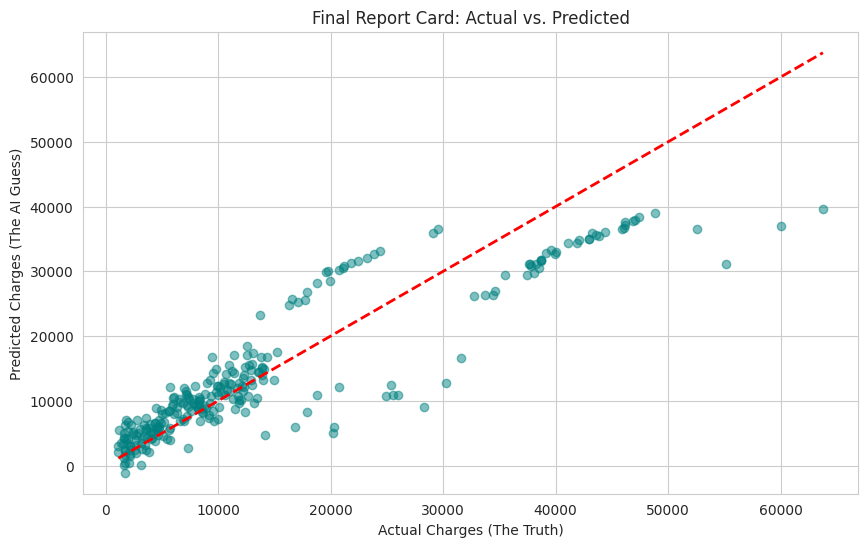

In [ ]:
plt.figure(figsize=(10, 6))

# Plotting Actual vs Predicted values
plt.scatter(Y_test, predictions, alpha=0.5, color='teal')

# Drawing the "Perfect Prediction" line
# If a dot is on this line, the AI was 100% right
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)

plt.xlabel('Actual Charges (The Truth)')
plt.ylabel('Predicted Charges (The AI Guess)')
plt.title('Final Report Card: Actual vs. Predicted')
plt.show()